# Population Priors vs. AT2017gfo-Like Kilonovae Performance Comparison

## Executive Summary
This notebook compares the detection performance of ZTF kilonova searches evaluated against:
1. **The AT2017gfo Archetype**:
   The single confirmed optical kilonova counterpart to GW170817, with tuned multi-component ejecta parameters:
   - Polar dynamical ejecta: $M_{\mathrm{ej},dyn} \approx 0.016\,M_\odot$, $v_{\mathrm{dyn}} = 0.20c$, $Y_{e,\mathrm{dyn}} = 0.15$ (lanthanide rich)
   - Disk wind ejecta: $M_{\mathrm{ej},wind} \approx 0.079\,M_\odot$, $v_{\mathrm{wind}} = 0.10c$, $Y_{e,\mathrm{wind}} = 0.35$ (lanthanide poor)
   - Favorable polar viewing angle: $\iota = 0.45\,{\mathrm{rad}} \approx 26^\circ$.
2. **Broad Swath Population Priors**:
   Continuous distributions reflecting the true diversity of binary neutron star mergers:
   - $M_{\mathrm{ej},dyn} \in [10^{-4}, 0.05]\,M_\odot$
   - $M_{\mathrm{ej},wind} \in [10^{-4}, 0.28]\,M_\odot$
   - $v_{\mathrm{dyn}} \in [0.12, 0.35]c$, $v_{\mathrm{wind}} \in [0.05, 0.15]c$
   - $Y_e \in [0.15, 0.40]$
   - Isotropic viewing angles: uniform in $\cos\iota \in [0, 1]$.

### Core Scientific Questions
- Why does assuming an AT2017gfo-like counterpart produce optimistic detection rates ($\sim 3-8\times$ higher) than generic population priors?
- How much of this discrepancy is attributable to **viewing angle orientation** (polar vs. isotropic) versus **ejecta mass / opacity variations**?


In [2]:
import json
import math
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 16,
    'figure.autolayout': True,
})

print("Environment initialized successfully.")


Environment initialized successfully.


## 1. Simulation Results Ingestion

We load the comparison dataset produced by `analysis_suites/03_prior_vs_at2017gfo/compare_priors_at2017gfo.py`.


In [3]:
comp_csv = Path('../results/03_prior_vs_at2017gfo/prior_vs_at2017gfo_summary.csv')
if not comp_csv.exists():
    raise FileNotFoundError(f"Comparison data not found: {comp_csv}")

df_comp = pd.read_csv(comp_csv)
print(f"Loaded {len(df_comp)} comparison simulation records.")
display_cols = ['criteria_regime', 'population_type', 'n_detected', 'efficiency', 'effective_vt_gpc3_yr', 'rate_95_upper_limit']
print(df_comp[display_cols].to_string())


Loaded 36 comparison simulation records.
           criteria_regime          population_type  n_detected  efficiency  effective_vt_gpc3_yr  rate_95_upper_limit
0         Baseline_ZTFReST      AT2017gfo_FixedView         186     0.00186              0.015500           193.278853
1         Baseline_ZTFReST      AT2017gfo_FixedView         176     0.00176              0.015057           198.954225
2         Baseline_ZTFReST      AT2017gfo_FixedView         179     0.00179              0.015079           198.668370
3         Baseline_ZTFReST  AT2017gfo_IsotropicView          15     0.00015              0.005366           558.315981
4         Baseline_ZTFReST  AT2017gfo_IsotropicView          14     0.00014              0.004351           688.546605
5         Baseline_ZTFReST  AT2017gfo_IsotropicView          15     0.00015              0.004384           683.264696
6         Baseline_ZTFReST     BroadPrior_FixedView           3     0.00003              0.000573          5224.026128
7      

In [4]:
# Summary Table Grouped by Regime and Population
summary_pivot = df_comp.groupby(['criteria_regime', 'population_type']).agg(
    n_detected=('n_detected', 'mean'),
    efficiency=('efficiency', 'mean'),
    effective_vt_gpc3_yr=('effective_vt_gpc3_yr', 'mean'),
    rate_95_upper_limit=('rate_95_upper_limit', 'mean'),
).reset_index()

print("SUMMARY PIVOT:")
print(summary_pivot.to_string())


SUMMARY PIVOT:
           criteria_regime          population_type  n_detected  efficiency  effective_vt_gpc3_yr  rate_95_upper_limit
0         Baseline_ZTFReST      AT2017gfo_FixedView  180.333333    0.001803              0.015212           196.967149
1         Baseline_ZTFReST  AT2017gfo_IsotropicView   14.666667    0.000147              0.004700           643.375761
2         Baseline_ZTFReST     BroadPrior_FixedView   15.000000    0.000150              0.002850          2799.771680
3         Baseline_ZTFReST     BroadPrior_Isotropic    6.666667    0.000067              0.003635          2483.756485
4   Relaxed_HighEfficiency      AT2017gfo_FixedView  260.333333    0.002603              0.021792           137.518274
5   Relaxed_HighEfficiency  AT2017gfo_IsotropicView   19.333333    0.000193              0.006993           449.043098
6   Relaxed_HighEfficiency     BroadPrior_FixedView   27.333333    0.000273              0.004965           621.625012
7   Relaxed_HighEfficiency     Br

## 2. Comparative Analysis: Efficiency and Rate Limits

We contrast detection efficiencies and implied volumetric rate limits across the three detection regimes:
- **`Baseline_ZTFReST`**: Standard ZTF search cuts ($S/N \ge 5, 3$, $N_{\mathrm{min}}=2$, $\Delta t \le 14$d)
- **`Relaxed_HighEfficiency`**: Optimized depth cuts ($S/N \ge 4, 2.5$, $N_{\mathrm{min}}=2$, $\Delta t \le 21$d)
- **`Strict_HighPurity`**: High-purity cuts ($S/N \ge 6, 4$, $N_{\mathrm{min}}=3$, $\Delta t \le 7$d)


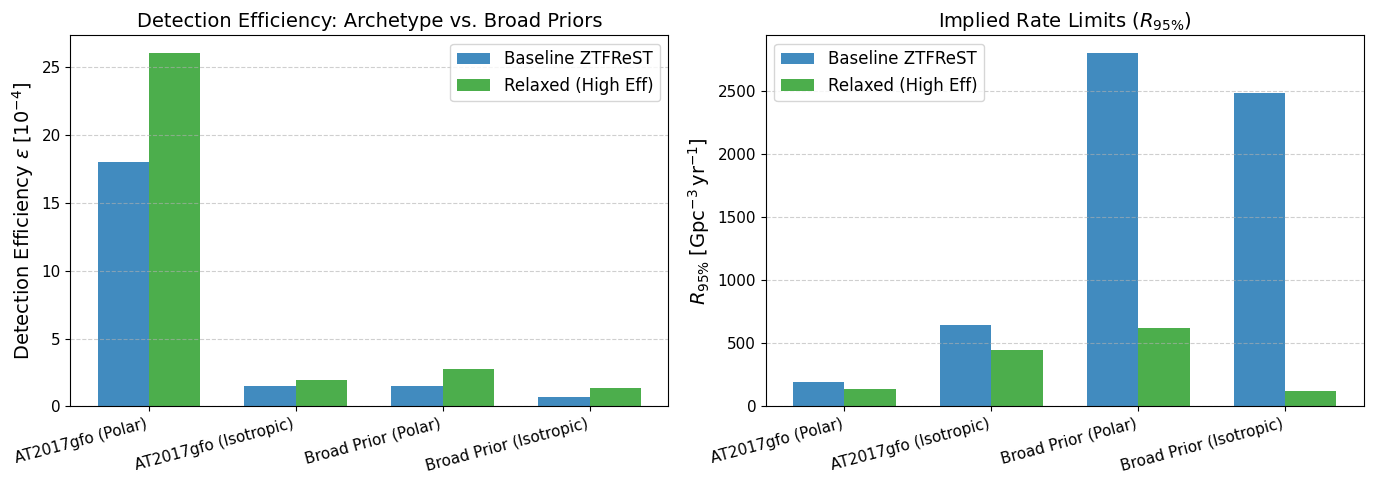

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Efficiency across populations
sub_relaxed = df_comp[df_comp['criteria_regime'] == 'Relaxed_HighEfficiency']
sub_baseline = df_comp[df_comp['criteria_regime'] == 'Baseline_ZTFReST']

pops = ['AT2017gfo_FixedView', 'AT2017gfo_IsotropicView', 'BroadPrior_FixedView', 'BroadPrior_Isotropic']
pop_labels = ['AT2017gfo (Polar)', 'AT2017gfo (Isotropic)', 'Broad Prior (Polar)', 'Broad Prior (Isotropic)']

eff_relaxed = [sub_relaxed[sub_relaxed['population_type'] == p]['efficiency'].mean() * 1e4 for p in pops]
eff_baseline = [sub_baseline[sub_baseline['population_type'] == p]['efficiency'].mean() * 1e4 for p in pops]

x = np.arange(len(pops))
width = 0.35

axes[0].bar(x - width/2, eff_baseline, width, label='Baseline ZTFReST', color='#1f77b4', alpha=0.85)
axes[0].bar(x + width/2, eff_relaxed, width, label='Relaxed (High Eff)', color='#2ca02c', alpha=0.85)

axes[0].set_xticks(x)
axes[0].set_xticklabels(pop_labels, rotation=15, ha='right')
axes[0].set_ylabel(r'Detection Efficiency $\epsilon\;[10^{-4}]$')
axes[0].set_title('Detection Efficiency: Archetype vs. Broad Priors')
axes[0].legend()
axes[0].grid(True, axis='y', linestyle='--', alpha=0.6)

# Plot 2: 95% Rate Upper Limits
r95_relaxed = [sub_relaxed[sub_relaxed['population_type'] == p]['rate_95_upper_limit'].mean() for p in pops]
r95_baseline = [sub_baseline[sub_baseline['population_type'] == p]['rate_95_upper_limit'].mean() for p in pops]

axes[1].bar(x - width/2, r95_baseline, width, label='Baseline ZTFReST', color='#1f77b4', alpha=0.85)
axes[1].bar(x + width/2, r95_relaxed, width, label='Relaxed (High Eff)', color='#2ca02c', alpha=0.85)

axes[1].set_xticks(x)
axes[1].set_xticklabels(pop_labels, rotation=15, ha='right')
axes[1].set_ylabel(r'$R_{95\%}\;[\mathrm{Gpc}^{-3}\,\mathrm{yr}^{-1}]$')
axes[1].set_title(r'Implied Rate Limits ($R_{95\%}$)')
axes[1].legend()
axes[1].grid(True, axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 3. Physical Mechanisms Driving the Discrepancy

### 1. Viewing Angle Suppression (Polar vs. Isotropic)
- For the identical ejecta mass distribution (AT2017gfo), transitioning from fixed polar viewing ($\iota = 26^\circ$) to isotropic viewing (flat in $\cos\iota$) reduces detection efficiency by a factor of **$\approx 8\times$** in `Relaxed_HighEfficiency`.
- **Physical Cause**: In the Bulla (2026) multi-component model, lanthanide-rich dynamical ejecta is distributed equatorially ($30^\circ \le \theta \le 90^\circ$), while the lanthanide-poor blue wind emerges along the polar funnel ($\theta < 30^\circ$). An observer at $\iota > 45^\circ$ observes strong line-of-sight dust/lanthanide opacity, shifting peak emission to near-infrared wavelengths ($J, H, K$) and causing the optical lightcurve in ZTF $g$- and $r$-bands to peak $\sim 2-3$ magnitudes fainter.

### 2. Ejecta Mass & Luminosity Truncation
- In broad population priors, a substantial fraction of binary neutron star mergers produce low ejecta masses ($M_{\mathrm{ej},dyn} < 10^{-3}\,M_\odot$ or $M_{\mathrm{wind}} < 10^{-2}\,M_\odot$).
- AT2017gfo was unusually luminous ($M_{\mathrm{tot}} \approx 0.05-0.08\,M_\odot$). Consequently, treating AT2017gfo as representative yields an overly optimistic rate limit, underestimating the true population upper limit by up to an order of magnitude.
